In [1]:
import pandas as pd
df = pd.read_csv("../data/Dataset.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(8790, 10)
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

Path("../screenshots").mkdir(exist_ok=True)
df = pd.read_csv("../data/Dataset.csv")
df.columns = df.columns.str.strip().str.lower()
print(df.shape); print(df.columns.tolist())

# numeric features
df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce")
dur = df["duration"].astype(str).str.extract(r"(\d+)")[0].astype(float)
is_tv = df["type"].astype(str).str.contains("TV", case=False)
df["movie_minutes"] = np.where(~is_tv, dur, 0)
df["tv_seasons"] = np.where(is_tv, dur, 0)

# categorical features (keep only the most common values)
df["main_genre"] = df["listed_in"].astype(str).str.split(",").str[0].str.strip()
df["main_country"] = df["country"].fillna("Unknown").astype(str).str.split(",").str[0].str.strip()
def top_n(s, n):
    keep = s.value_counts().nlargest(n).index
    return s.where(s.isin(keep), "Other")
df["main_genre"] = top_n(df["main_genre"], 8)
df["main_country"] = top_n(df["main_country"], 6)
df["rating"] = df["rating"].fillna("Unknown")

num_cols = ["release_year", "movie_minutes", "tv_seasons"]
cat_cols = ["type", "rating", "main_genre", "main_country"]
data = df[num_cols + cat_cols].copy()
data[num_cols] = data[num_cols].fillna(data[num_cols].median())
X = pd.get_dummies(data, columns=cat_cols, drop_first=False).astype(float)
print(X.shape)

(8790, 10)
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']
(8790, 35)


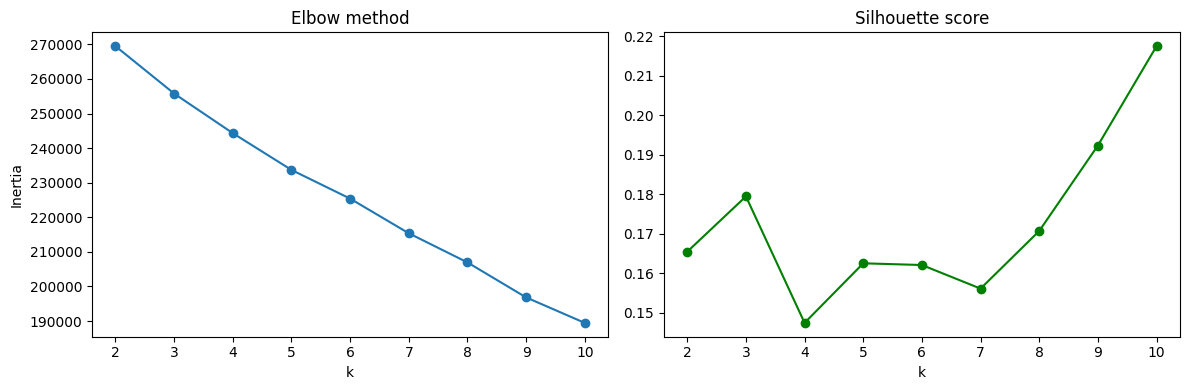

Best k by silhouette: 10


In [3]:
X_scaled = StandardScaler().fit_transform(X)

ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_, sample_size=3000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(ks, sil, "o-", color="green"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.savefig("../screenshots/01_elbow_silhouette.png", dpi=150); plt.show()

best_k = list(ks)[int(np.argmax(sil))]
print("Best k by silhouette:", best_k)

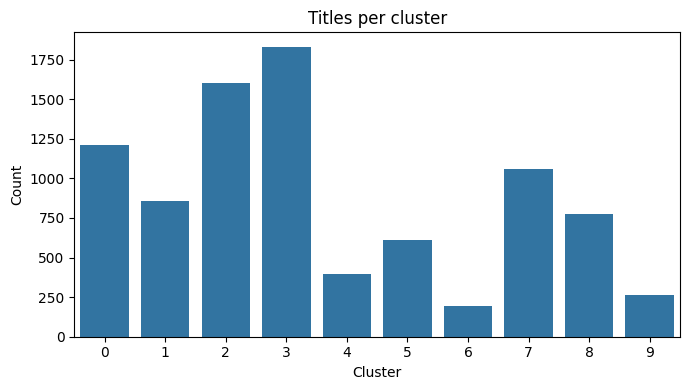

Silhouette: 0.217


In [4]:
K = best_k   # change this number if you prefer another k after looking at the plots
km = KMeans(n_clusters=K, random_state=42, n_init=10).fit(X_scaled)
df["cluster"] = km.labels_

sizes = df["cluster"].value_counts().sort_index()
plt.figure(figsize=(7, 4))
sns.barplot(x=sizes.index, y=sizes.values)
plt.title("Titles per cluster"); plt.xlabel("Cluster"); plt.ylabel("Count")
plt.tight_layout(); plt.savefig("../screenshots/02_cluster_sizes.png", dpi=150); plt.show()
print("Silhouette:", round(silhouette_score(X_scaled, km.labels_, sample_size=3000, random_state=42), 3))

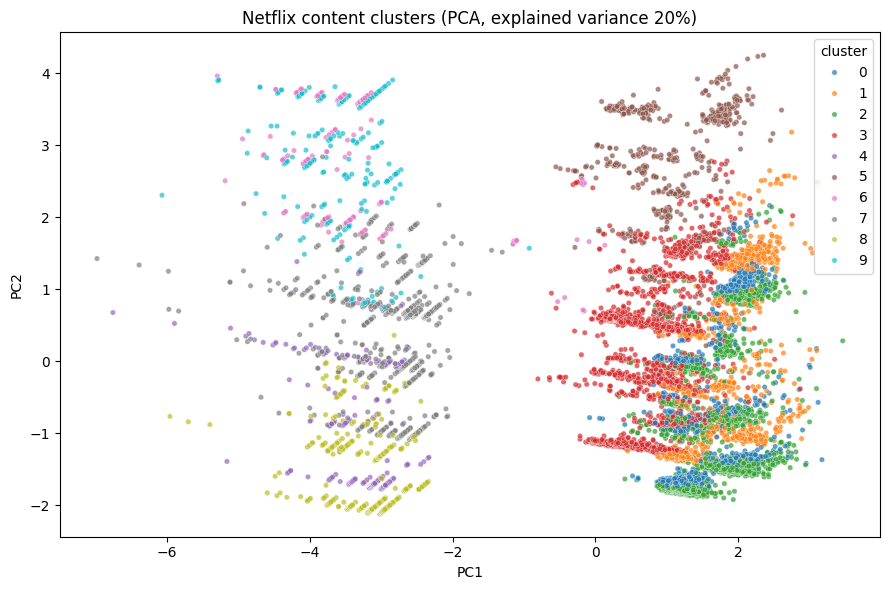

In [5]:
pca = PCA(n_components=2, random_state=42)
pts = pca.fit_transform(X_scaled)
plt.figure(figsize=(9, 6))
sns.scatterplot(x=pts[:, 0], y=pts[:, 1], hue=df["cluster"], palette="tab10", s=15, alpha=0.7)
plt.title(f"Netflix content clusters (PCA, explained variance {pca.explained_variance_ratio_.sum():.0%})")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout(); plt.savefig("../screenshots/03_pca_clusters.png", dpi=150); plt.show()

,release_year,movie_minutes,tv_seasons,count,top_type,top_rating,top_main_genre,top_main_country
cluster,,,,,,,,
0,2013.0,106.7,0.0,1210,Movie,TV-MA,Comedies,Other
1,2009.5,113.5,0.0,859,Movie,R,Action & Adventure,United States
2,2014.0,111.4,0.0,1599,Movie,TV-MA,Dramas,Other
3,2013.9,85.6,0.0,1830,Movie,TV-MA,Other,United States
4,2017.9,0.0,1.7,399,TV Show,TV-MA,Crime TV Shows,Other
5,2013.8,78.9,0.0,609,Movie,PG,Children & Family Movies,United States
6,2016.9,3.4,1.7,193,TV Show,TV-Y,Kids' TV,United States
7,2016.3,0.0,2.0,1057,TV Show,TV-MA,Other,United States
8,2016.8,0.0,1.3,773,TV Show,TV-MA,International TV Shows,Other


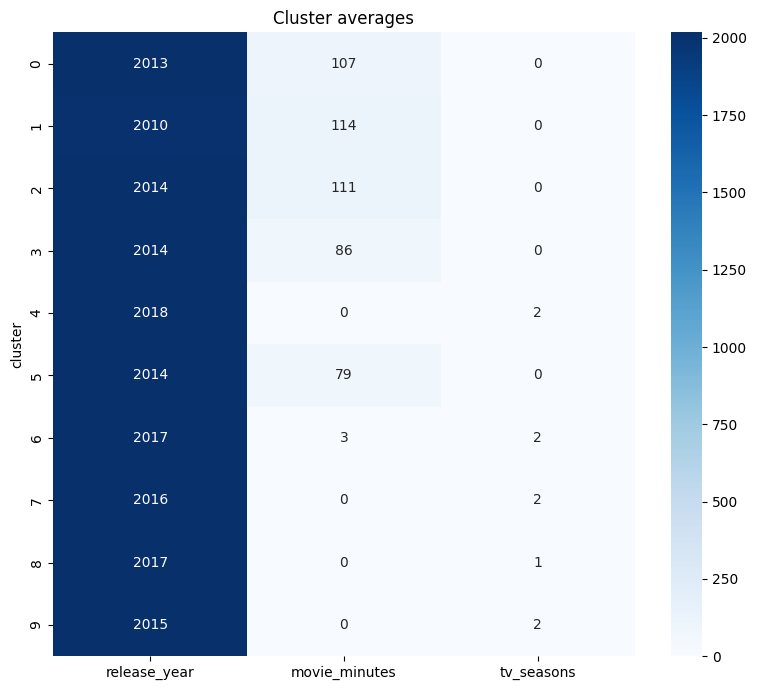

Cluster 0: 1210 titles, mostly Movie / Comedies / TV-MA / Other, avg year 2013
Cluster 1: 859 titles, mostly Movie / Action & Adventure / R / United States, avg year 2010
Cluster 2: 1599 titles, mostly Movie / Dramas / TV-MA / Other, avg year 2014
Cluster 3: 1830 titles, mostly Movie / Other / TV-MA / United States, avg year 2014
Cluster 4: 399 titles, mostly TV Show / Crime TV Shows / TV-MA / Other, avg year 2018
Cluster 5: 609 titles, mostly Movie / Children & Family Movies / PG / United States, avg year 2014
Cluster 6: 193 titles, mostly TV Show / Kids' TV / TV-Y / United States, avg year 2017
Cluster 7: 1057 titles, mostly TV Show / Other / TV-MA / United States, avg year 2016
Cluster 8: 773 titles, mostly TV Show / International TV Shows / TV-MA / Other, avg year 2017
Cluster 9: 261 titles, mostly TV Show / Kids' TV / TV-Y7 / United States, avg year 2015


In [7]:
num_profile = df.groupby("cluster")[["release_year", "movie_minutes", "tv_seasons"]].mean().round(1)
num_profile["count"] = df["cluster"].value_counts().sort_index()
for c in ["type", "rating", "main_genre", "main_country"]:
    num_profile[f"top_{c}"] = df.groupby("cluster")[c].agg(lambda s: s.mode().iloc[0])
display(num_profile)

fig, ax = plt.subplots(figsize=(8, 3 + K * 0.4))
sns.heatmap(num_profile[["release_year", "movie_minutes", "tv_seasons"]], annot=True, fmt=".0f", cmap="Blues", ax=ax)
plt.title("Cluster averages"); plt.tight_layout()
plt.savefig("../screenshots/04_cluster_profile.png", dpi=150); plt.show()

for c in range(K):
    r = num_profile.loc[c]
    print(f"Cluster {c}: {int(r['count'])} titles, mostly {r['top_type']} / {r['top_main_genre']} / {r['top_rating']} / {r['top_main_country']}, avg year {r['release_year']:.0f}")